[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/santialferez/FDLE/blob/main/S2_CNN/S2_CNN_STUDENT.ipynb)

# CNN II: architectures, Grad-CAM and transfer learning

**Foundations of Deep Learning for Engineering · Convolutional networks, Session 2 of 2 (week 9)** · EEBE, UPC

Last week you built a small CNN. Today you look inside famous CNNs and reuse one:

1. **Architectures**: where VGG-16 keeps its 138 million parameters, and why ResNet adds its input back (y = x + F(x)),
2. **What a CNN looks at**: first-layer filters, Grad-CAM heat maps, and an image that fools the network,
3. **Transfer learning**: a ResNet18 trained on ImageNet learns CIFAR-10 from only 5,000 images,
4. **Segmentation**: a class for every pixel.

Work **in pairs** in Google Colab. *Runtime → Change runtime type → T4 GPU*.

**Start now:** run `S2·0` (Part 0, about 40 s), then do the warm-up W1 to W4 on your own. Each lab of the session is a short block of cells; every lab works after `S2·0` alone, so if you are stuck in one lab you can still do the next one.

### How to use this notebook

| Icon | Meaning |
|:-:|:-|
| ▶ | run the cell as it is |
| ✏️ **TODO** | complete the code: replace every `___` with the right expression |
| ❓ | closed question: choose an option or give a number |
| 💬 | open question: discuss with your partner and write two or three sentences |
| 🔬 | experiment: change a setting and watch what happens |
| ✅ | self-check: prints ✅ when your code is right |
| ★ | optional extra for fast pairs: skip it if you are short of time |
| **REPORT** | the last line of each lab: the numbers you say aloud and type into Moodle, exactly as printed |

Nothing in this notebook is graded. Change things, break things, and compare.

**About LLMs.** You may use an LLM (ChatGPT, Claude, Gemini, ...) to understand an error message or a concept. Do not use it to fill the blanks: the blanks are exactly the lines you should be able to write yourself.

## Outline

Run **Part 0** first. The warm-up is for the first 25 minutes, on your own. Each lab is a short block of cells done in pairs at the time in the table; it ends with a **REPORT** line. Every lab works after Part 0 alone.

| Part | Clock | Steps | You report | Slides |
|:-|:-:|:-|:-|:-:|
| Part 0 · Setup | 12:00, first thing | ▶ S2·0 |  |  |
| Warm-up · Finish Session 1 | 12:00 to 12:25 | ✏️ W1 · ✏️ W2 · ✏️ W3 · ▶ W4 · ❓ | CIFAR-10 accuracy (%) of the MLP and of your CNN | 2 |
| Lab 1 · Look inside VGG-16 and ResNet18 | 12:52 to 13:08 | ▶ L1·1 · ✏️ TODO 1 · ✏️ TODO 2 · ✏️ TODO 3 · ▶ L1·3 · ★ optional · 💬 ❓ | % of the parameters in the FC layers (VGG-16, ResNet18) and the gradient ratio skip/plain | 8, 9, 10 |
| Lab 2 · Grad-CAM, then fool the network | 13:26 to 13:43 | ▶ L2·1 · ✏️ TODO 1 · ✏️ TODO 2 · ★ optional · 💬 ❓ | the hottest Grad-CAM cell (row, col), the smallest ε that changes the class, and the new class | 14, 15, 16 |
| Lab 3 · Transfer learning: reuse 11 million weights | 14:33 to 15:03 (3a until 14:46) | ▶ L3·1 · ▶ L3·2 · ✏️ TODO 1 · ✏️ TODO 2 · 🔬 TODO 3 · ★ optional · ❓ ❓ 💬 | accuracy (%) after feature extraction (3a); after fine-tuning (3b); with a learning rate 100 times too large (🔬) | 20, 21, 22 |
| Lab 4 · Upsample, then segment the cat | 15:27 to 15:36 | ✏️ TODO 1 · ▶ L4·2 · ★ optional · ❓ | the % of the pixels of the cat photo labelled "cat" | 27, 29 |
| Summary | 15:42 |  |  |  |

Slide numbers are those of the lecture deck (title slide = 1).

## Part 0 · Setup ▶

Run this cell first (about 40 s on a T4). It:

- imports the libraries and finds the GPU,
- defines the helpers of Session 1: `check`, `set_seed`, `count_params`, `evaluate`, `fit`, `show_results`, `show_grid`, and `report_line`, which prints the **REPORT** line of each lab,
- loads CIFAR-10 (50,000 training and 10,000 test photos, 3 × 32 × 32),
- loads **ResNet18 pretrained on ImageNet** (11.7 million parameters, 1,000 classes) and the names of its classes,
- loads four test photos: a cat, an astronaut, a coffee cup and a rocket.

In [ ]:
# ▶ S2·0
import os, io, time, json, copy, random, contextlib, warnings, urllib.request
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
import torch.nn.functional as F
import torchvision
from torchvision.models import ResNet18_Weights

T0_SETUP = time.time()
FAST = os.environ.get("FAST") == "1"      # FAST=1: tiny subsets and 1 epoch (only to test the notebook on a CPU)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "· torchvision", torchvision.__version__, "· device:", device,
      "· FAST mode" if FAST else "")
if device == "cpu":
    print("No GPU: Runtime → Change runtime type → T4 GPU (the notebook also runs on a CPU, only much slower).")
with warnings.catch_warnings():            # same arithmetic on every GPU: no TF32 (a T4 has none anyway)
    warnings.simplefilter("ignore")
    try:
        torch.backends.cuda.matmul.allow_tf32 = False
        torch.backends.cudnn.allow_tf32 = False
    except Exception:
        pass

MLP_COLOR, CNN_COLOR = "#C9423A", "#1F8A8A"     # red = MLP, teal = CNN in every chart
RESULTS = []                                     # one row per trained model (filled by fit and train_tl)
REPORTS = {}                                     # the REPORT line of each lab


def set_seed(s=0):
    """Same seed -> same random numbers -> same results (reproducibility)."""
    random.seed(s)
    np.random.seed(s)
    torch.manual_seed(s)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)


def check(cond, ok_msg, hint):
    """Self-check: prints ✅ when the condition holds, otherwise ❌ with a hint. Nothing is graded."""
    print(("✅ " + ok_msg) if cond else ("❌ Not yet. Hint: " + hint))


def count_params(model):
    """Number of trainable parameters (weights and biases with requires_grad=True)."""
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


@torch.no_grad()
def predict(model, X, batch_size=1000):
    """Predicted class of every image in X (in batches, so the GPU memory is enough)."""
    model.eval()
    return torch.cat([model(X[i:i + batch_size]).argmax(dim=1) for i in range(0, len(X), batch_size)])


def evaluate(model, X, y):
    """Accuracy of the model on images X with labels y: a number between 0 and 1."""
    return (predict(model, X) == y).float().mean().item()


def fit(model, X_train, y_train, X_val, y_val, epochs=2, lr=1e-3, batch_size=128, name=None):
    """Mini-batch training with Adam and cross-entropy (Session 1); the data stay on `device`.
    Prints one line per epoch, returns dict(train_loss, val_acc) and adds a row to RESULTS."""
    name = name or model.__class__.__name__
    model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()              # takes logits: no softmax in forward
    hist = dict(train_loss=[], val_acc=[])
    n, t0 = len(X_train), time.time()
    for epoch in range(epochs):
        model.train()
        perm = torch.randperm(n, device=X_train.device)
        total = torch.zeros((), device=X_train.device)
        for i in range(0, n, batch_size):
            idx = perm[i:i + batch_size]
            xb, yb = X_train[idx], y_train[idx]
            loss = loss_fn(model(xb), yb)        # 1. forward, 2. loss
            optimizer.zero_grad()
            loss.backward()                      # 3. backward (gradients)
            optimizer.step()                     # 4. update the parameters
            total += loss.detach() * len(idx)
        hist["train_loss"].append(total.item() / n)
        hist["val_acc"].append(evaluate(model, X_val, y_val))
        print(f"{name} · epoch {epoch + 1}/{epochs} · train loss {hist['train_loss'][-1]:.4f} · "
              f"val acc {100 * hist['val_acc'][-1]:.1f}% · {time.time() - t0:.0f} s")
    acc = hist["val_acc"][-1]
    RESULTS.append(dict(name=name, params=count_params(model), val_acc=acc,
                        errors=int(round((1 - acc) * len(y_val))), n_val=len(y_val),
                        epochs=epochs, time_s=round(time.time() - t0, 1)))
    return hist


def result(name):
    """The last row of RESULTS with this name."""
    return [r for r in RESULTS if r["name"] == name][-1]


def show_results():
    """Print the table of every model trained so far."""
    print(f"{'model':42s} {'params':>11s} {'val acc':>8s}   {'time':>6s}")
    for r in RESULTS:
        print(f"{r['name']:42s} {r['params']:>11,} {100 * r['val_acc']:7.1f}%   {r['time_s']:5.1f} s")


def show_grid(images, titles=None, ncols=8, size=1.4, cmap="gray"):
    """Show a few images (N, C, H, W) or (N, H, W) in a grid; each image is scaled to [0, 1]."""
    images = images.detach().float().cpu()
    if images.ndim == 3:
        images = images.unsqueeze(1)
    n = len(images)
    nrows = (n + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(size * ncols, size * nrows * 1.15), squeeze=False)
    for i, ax in enumerate(axes.flat):
        ax.axis("off")
        if i >= n:
            continue
        im = images[i]
        im = (im - im.min()) / (im.max() - im.min() + 1e-8)
        if im.shape[0] == 1:
            ax.imshow(im[0], cmap=cmap)
        else:
            ax.imshow(im.permute(1, 2, 0))
        if titles is not None and i < len(titles) and titles[i]:
            ax.set_title(titles[i], fontsize=9)
    plt.tight_layout(); plt.show()


def report_line(lab, text):
    """Print the REPORT line of a lab (say it aloud, type the numbers into Moodle) and keep it for the summary."""
    REPORTS[lab] = text
    print(f"REPORT: {text}")


def report():
    """Every REPORT line of the session, in one table."""
    if not REPORTS:
        print("No REPORT line yet: run the labs first.")
    for lab, text in REPORTS.items():
        print(f"{lab:10s} REPORT: {text}")


# ---- reference numbers (the lecturer's slides and quizzes use them; you can ignore this)
REF = {"warmup": {"mlp": {"params": None, "val_acc": None, "time_s": None},
                  "cnn": {"params": None, "val_acc": None, "time_s": None}},
       "lab1": {"vgg_total": None, "vgg_fc1": None, "vgg_fc_share": None, "resnet_total": None,
                "resnet_fc_share": None, "grad_plain": None, "grad_skip": None, "grad_ratio": None,
                "top1": {"cat": None, "astronaut": None, "coffee": None, "rocket": None}},
       "lab2": {"cam_class": None, "cam_cell": None, "fgsm_eps": None, "fgsm_class": None},
       "lab3": {"n_train": None, "n_val": None, "img_size": None,
                "scratch5k": {"val_acc": None, "time_s": None},
                "fe": {"val_acc": None, "time_s": None, "trainable": None},
                "ft": {"val_acc": None, "time_s": None, "trainable": None},
                "bad_lr": {"val_acc": None, "time_s": None}},
       "lab4": {"up_shape": None, "cat_pct": None},
       "device": device, "gpu": torch.cuda.get_device_name(0) if device == "cuda" else "cpu",
       "torch": torch.__version__, "fast": FAST}


def save_reference(path=None, quiet=False):
    """Write REF to s2_reference.json (s2_reference_fast.json under FAST). Never raises."""
    try:
        path = path or ("s2_reference_fast.json" if FAST else "s2_reference.json")
        with open(path, "w") as f:
            json.dump(REF, f, indent=1, ensure_ascii=False)
        if not quiet:
            print("reference numbers written to", os.path.abspath(path))
    except Exception as e:                                # never break the notebook
        print("(could not write the reference file:", repr(e)[:100], ")")


# ---- CIFAR-10 as uint8 tensors (N, 3, 32, 32) on the CPU; each lab makes its own float copies
DATA = "./data"
CIFAR_CLASSES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
HF_CIFAR = "https://huggingface.co/datasets/uoft-cs/cifar10/resolve/main/plain_text/"


def cifar10_local(split):
    """A copy already on disk (torchvision format), no download."""
    ds = torchvision.datasets.CIFAR10(DATA, train=(split == "train"), download=False)
    return ds.data, torch.tensor(ds.targets)


def cifar10_from_huggingface(split):
    """The official CIFAR-10 mirrored on Hugging Face (parquet, PNG bytes). Fast from Colab."""
    import pandas as pd
    from PIL import Image
    df = pd.read_parquet(HF_CIFAR + f"{split}-00000-of-00001.parquet")
    imgs = np.stack([np.array(Image.open(io.BytesIO(d["bytes"]))) for d in df["img"]])  # (N, 32, 32, 3) uint8
    return imgs, torch.tensor(df["label"].to_numpy())


def cifar10_from_torchvision(split):
    """The original site (www.cs.toronto.edu), sometimes very slow."""
    ds = torchvision.datasets.CIFAR10(DATA, train=(split == "train"), download=True)
    return ds.data, torch.tensor(ds.targets)


loaders = [("Hugging Face mirror", cifar10_from_huggingface), ("original site (slow)", cifar10_from_torchvision)]
if os.path.isdir(os.path.join(DATA, "cifar-10-batches-py")):
    loaders.insert(0, ("copy in ./data", cifar10_local))
CIFAR_OK = False
for where, load in loaders:
    try:
        tr_np, CIFAR_Y_TRAIN = load("train")
        te_np, CIFAR_Y_TEST = load("test")
        CIFAR_X_TRAIN = torch.as_tensor(np.asarray(tr_np)).permute(0, 3, 1, 2).contiguous()   # uint8
        CIFAR_X_TEST = torch.as_tensor(np.asarray(te_np)).permute(0, 3, 1, 2).contiguous()
        CIFAR_OK = True
        print(f"CIFAR-10 from the {where}")
        break
    except Exception as e:
        print(f"CIFAR-10 from the {where} failed:", repr(e)[:100])
if not CIFAR_OK:                                  # last resort: Fashion-MNIST made to look like CIFAR-10
    print("-> using Fashion-MNIST instead (resized to 3 × 32 × 32)")
    f_tr = torchvision.datasets.FashionMNIST(DATA, train=True, download=True)
    f_te = torchvision.datasets.FashionMNIST(DATA, train=False, download=True)

    def to_3x32(x):
        x = F.interpolate(x.unsqueeze(1).float(), size=32, mode="bilinear", align_corners=False)
        return x.round().clamp(0, 255).to(torch.uint8).repeat(1, 3, 1, 1)

    CIFAR_X_TRAIN, CIFAR_Y_TRAIN = to_3x32(f_tr.data), f_tr.targets.clone()
    CIFAR_X_TEST, CIFAR_Y_TEST = to_3x32(f_te.data), f_te.targets.clone()
    CIFAR_CLASSES = f_tr.classes
print(f"train {tuple(CIFAR_X_TRAIN.shape)} · test {tuple(CIFAR_X_TEST.shape)} · uint8 · CIFAR_OK = {CIFAR_OK}")

# ---- ResNet18 pretrained on ImageNet (45 MB, downloaded once) and its 1,000 class names
weights = ResNet18_Weights.DEFAULT
categories = weights.meta["categories"]
resnet = torchvision.models.resnet18(weights=weights).eval().to(device)
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)


def imagenet_norm(x):
    """Pixels in [0, 1] -> the normalization ResNet18 was trained with (ImageNet mean and std per channel)."""
    return (x - IMAGENET_MEAN.to(x.device)) / IMAGENET_STD.to(x.device)


# ---- four photos from scikit-image (no download; GitHub as a fallback)
PHOTO_FILES = {"cat": ("chelsea", "png"), "astronaut": ("astronaut", "png"),
               "coffee": ("coffee", "png"), "rocket": ("rocket", "jpg")}


def get_photo(key):
    """RGB uint8 array (H, W, 3) of one test photo."""
    name, ext = PHOTO_FILES[key]
    try:
        import skimage.data
        return getattr(skimage.data, name)()
    except Exception:
        pass
    try:
        from PIL import Image
        url = f"https://raw.githubusercontent.com/scikit-image/scikit-image/main/skimage/data/{name}.{ext}"
        with urllib.request.urlopen(url, timeout=20) as r:
            return np.array(Image.open(io.BytesIO(r.read())).convert("RGB"))
    except Exception:
        print(f"(photo '{key}' not found: using a CIFAR-10 test image instead)")
        return CIFAR_X_TEST[{"cat": 0, "astronaut": 1, "coffee": 2, "rocket": 3}[key]].permute(1, 2, 0).numpy()


def to_tensor(arr):
    """uint8 (H, W, 3) -> float (1, 3, H, W) with values in [0, 1]."""
    return torch.as_tensor(np.ascontiguousarray(arr)).permute(2, 0, 1).float().unsqueeze(0) / 255


def center_224(x, size=224):
    """Resize the short side to 224 and cut the central 224 × 224 square (what ResNet18 expects)."""
    h, w = x.shape[-2:]
    s = size / min(h, w)
    x = F.interpolate(x, size=(max(size, round(h * s)), max(size, round(w * s))), mode="bilinear",
                      antialias=True, align_corners=False)
    h, w = x.shape[-2:]
    top, left = (h - size) // 2, (w - size) // 2
    return x[..., top:top + size, left:left + size].clamp(0, 1)


PHOTOS_FULL = {k: to_tensor(get_photo(k)).to(device) for k in PHOTO_FILES}       # native size, for Lab 4
PHOTOS_224 = {k: center_224(x.cpu()).to(device) for k, x in PHOTOS_FULL.items()}  # (1, 3, 224, 224), Labs 1, 2
print("photos:", ", ".join(f"{k} {tuple(x.shape[-2:])}" for k, x in PHOTOS_FULL.items()))
print(f"ResNet18: {sum(p.numel() for p in resnet.parameters()):,} parameters, {len(categories)} classes")
print(f"setup ready in {time.time() - T0_SETUP:.0f} s")

## Warm-up · Finish Session 1 (on your own, 12:00 to 12:25)

*Slide: "Start now, in pairs" (slide 2).*

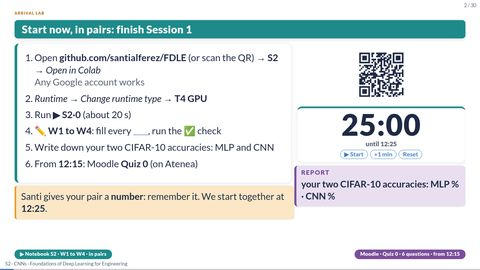

<sub>Slide 2 · Start now</sub>

Last week we ran out of time before the CIFAR-10 result. Finish it now, in pairs, without the lecturer:

1. **W1** and **W2**: the two formulas of Session 1 as Python functions.
2. **W3**: write the CIFAR-10 `ConvNet` yourself.
3. **W4**: train the MLP and your ConvNet on CIFAR-10 and write down the two accuracies.

Each ✏️ cell has blanks `___`. Replace them, run the cell, then run the ✅ cell below it. Stuck? Read the hint, ask the pair next to you. From 12:15 the Moodle Quiz 0 is open: its last question asks for your CNN accuracy from W4.

**You report:** CIFAR-10 accuracy (%) of the MLP and of your CNN

### ✏️ W1 · The output-size formula

For an input of size J, a kernel M, padding P and stride S, the output size is

$$\frac{J + 2P - M}{S} + 1 \quad\text{(rounded down)}$$

Write it with `//` (integer division).

In [ ]:
# ✏️ S2·W1
def out_size(J, M, P=0, S=1):
    """Output size of a convolution or pooling: input J, kernel M, padding P, stride S."""
    return (J + 2 * ___ - ___) // ___ + 1


print(out_size(28, 3, 1), out_size(32, 5), out_size(224, 7, 3, 2), out_size(28, 2, 0, 2))

In [ ]:
# ▶ S2·W1·check
check(out_size(28, 3, 1) == 28, "(28 + 2 − 3)/1 + 1 = 28: padding 1 keeps the size of a 3 × 3 conv",
      "2 * P, minus M, then // S, plus 1")
check(out_size(32, 5) == 28, "(32 − 5)/1 + 1 = 28 (LeNet's first layer)", "P = 0 and S = 1 by default")
check(out_size(224, 7, 3, 2) == 112, "(224 + 6 − 7)//2 + 1 = 112 (the first layer of ResNet18)",
      "use // for the division by S")
check(out_size(28, 2, 0, 2) == 14, "pooling 2 × 2 with stride 2: 28 → 14", "a pooling window is a kernel with M = 2, S = 2")

### ✏️ W2 · Parameters of a convolution

`nn.Conv2d(C_in, C_out, M)` has C_out filters. Each filter sees **all** the input channels, so it has M · M · C_in weights plus 1 bias:

$$(M^2 \cdot C_{in} + 1)\cdot C_{out}$$

In [ ]:
# ✏️ S2·W2
def conv_params(M, C_in, C_out):
    """Weights and biases of nn.Conv2d(C_in, C_out, M)."""
    return (M * M * ___ + 1) * ___


print(conv_params(3, 1, 8), conv_params(3, 8, 16), conv_params(3, 3, 8))

In [ ]:
# ▶ S2·W2·check
check(conv_params(3, 1, 8) == 80, "conv(1 → 8, 3 × 3): (9·1 + 1)·8 = 80", "M * M * C_in weights per filter, plus 1 bias")
check(conv_params(3, 8, 16) == 1168, "conv(8 → 16, 3 × 3): (9·8 + 1)·16 = 1,168", "each filter sees all 8 input channels")
check(conv_params(3, 3, 8) == 224 == count_params(nn.Conv2d(3, 8, 3)),
      "conv(3 → 8, 3 × 3) on colour images: (9·3 + 1)·8 = 224, the same as PyTorch", "multiply by C_out at the end")

### ✏️ W3 · Write the CIFAR-10 `ConvNet`

The ConvNet of Session 1, now for colour photos of 3 × 32 × 32 pixels:

| layer | output shape | parameters |
|:-|:-|-:|
| input | (N, 3, 32, 32) | |
| conv(3 → 8, 3 × 3, padding 1) + ReLU | (N, 8, 32, 32) | (9 · 3 + 1) · 8 = 224 |
| max-pool 2 | (N, 8, 16, 16) | 0 |
| conv(8 → 16, 3 × 3, padding 1) + ReLU | (N, 16, 16, 16) | (9 · 8 + 1) · 16 = 1,168 |
| max-pool 2 | (N, 16, 8, 8) | 0 |
| flatten | (N, 1,024) | 0 |
| Linear(1,024, 64) + ReLU | (N, 64) | 1,024 · 64 + 64 = 65,600 |
| Linear(64, 10) | (N, 10) | 650 |
| **total** | | **67,642** |

Fill in: the number of input channels, the padding that keeps 32 × 32, and the height × width after two poolings.

In [ ]:
# ✏️ S2·W3
class ConvNet(nn.Module):
    """conv(3→8) → ReLU → pool → conv(8→16) → ReLU → pool → flatten → Linear(1024, 64) → ReLU → Linear(64, 10)."""
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(___, 8, kernel_size=3, padding=___)    # colour photos: how many input channels?
        self.conv2 = nn.Conv2d(8, 16, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2)
        self.fc1 = nn.Linear(16 * ___, 64)                         # 16 channels × height × width after 2 poolings
        self.fc2 = nn.Linear(64, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))       # (N, 8, 16, 16)
        x = self.pool(F.relu(self.conv2(x)))       # (N, 16, 8, 8)
        x = F.relu(self.fc1(x.flatten(1)))         # (N, 64)
        return self.fc2(x)                         # (N, 10) logits, no softmax


set_seed(0)
cnn_w = ConvNet()
out = cnn_w(torch.randn(64, 3, 32, 32))
print("output", tuple(out.shape), "·", f"{count_params(cnn_w):,}", "parameters")

In [ ]:
# ▶ S2·W3·check
check(tuple(out.shape) == (64, 10), "64 photos in, 64 × 10 logits out", "conv1 needs 3 input channels (RGB)")
check(count_params(cnn_w) == 67642, "ConvNet on CIFAR-10 has 67,642 parameters (224 + 1,168 + 65,600 + 650)",
      "padding=1 keeps 32 × 32; two poolings give 32 → 16 → 8, so fc1 sees 16 · 8 · 8 = 1,024 numbers")

### ▶ W4 · CIFAR-10: MLP vs your ConvNet

Both models train 5 epochs on the 50,000 training photos (Adam, learning rate 0.001, batch 128) and are measured on the 10,000 test photos. About 10 s on a T4.

- MLP 3,072 → 64 → 10: 197,322 parameters (it flattens the 3 · 32 · 32 = 3,072 numbers),
- your ConvNet: 67,642 parameters, about one third.

**Predict first.** Which model will be more accurate? By how many points? Write your guess before you run the cell.

In [ ]:
# ▶ S2·W4
N_W, NV_W, EPOCHS_W = (10_000, 2_000, 1) if FAST else (50_000, 10_000, 5)
xw = CIFAR_X_TRAIN[:N_W].float() / 255
W_MEAN, W_STD = xw.mean(dim=(0, 2, 3), keepdim=True), xw.std(dim=(0, 2, 3), keepdim=True)   # per channel
Xw_train = ((xw - W_MEAN) / W_STD).to(device)
Xw_val = ((CIFAR_X_TEST[:NV_W].float() / 255 - W_MEAN) / W_STD).to(device)
yw_train, yw_val = CIFAR_Y_TRAIN[:N_W].to(device), CIFAR_Y_TEST[:NV_W].to(device)
del xw


class MLP(nn.Module):
    """flatten → Linear(3072, 64) → ReLU → Linear(64, 10)."""
    def __init__(self, in_features=3 * 32 * 32, hidden=64):
        super().__init__()
        self.net = nn.Sequential(nn.Flatten(), nn.Linear(in_features, hidden), nn.ReLU(), nn.Linear(hidden, 10))

    def forward(self, x):
        return self.net(x)                                # logits, no softmax


set_seed(0)
mlp_w, cnn_w = MLP(), ConvNet()
check(count_params(mlp_w) == 197322 and count_params(cnn_w) == 67642,
      "MLP 197,322 and ConvNet 67,642 parameters", "finish W3 first: the ConvNet must have 67,642 parameters")
fit(mlp_w, Xw_train, yw_train, Xw_val, yw_val, epochs=EPOCHS_W, name="MLP · CIFAR-10")
fit(cnn_w, Xw_train, yw_train, Xw_val, yw_val, epochs=EPOCHS_W, name="ConvNet · CIFAR-10")
r_mlp, r_cnn = result("MLP · CIFAR-10"), result("ConvNet · CIFAR-10")

plt.figure(figsize=(5.5, 3.4))
for k, (r, col, lab) in enumerate([(r_mlp, MLP_COLOR, "MLP"), (r_cnn, CNN_COLOR, "ConvNet")]):
    plt.bar(k, 100 * r["val_acc"], color=col, width=0.6)
    plt.text(k, 100 * r["val_acc"] + 1.5, f"{100 * r['val_acc']:.1f}%\n{r['params']:,} params", ha="center", fontsize=9)
plt.xticks([0, 1], ["MLP", "ConvNet"]); plt.ylim(0, 100); plt.ylabel("validation accuracy (%)")
plt.title("CIFAR-10: a third of the parameters, more accuracy"); plt.tight_layout(); plt.show()

for key, r in (("mlp", r_mlp), ("cnn", r_cnn)):
    REF["warmup"][key] = {"params": r["params"], "val_acc": round(r["val_acc"], 4), "time_s": r["time_s"]}
save_reference(quiet=True)
thr_mlp, thr_cnn = (0.30, 0.28) if FAST else (0.45, 0.58)    # reference run (Colab T4): MLP 49.0%, CNN 62.4%
check(r_mlp["val_acc"] > thr_mlp and r_cnn["val_acc"] > thr_cnn,
      f"MLP {100 * r_mlp['val_acc']:.1f}% · ConvNet {100 * r_cnn['val_acc']:.1f}%",
      "rerun W3 and this cell (the models are created again here)")
if not FAST:
    check(r_cnn["val_acc"] > r_mlp["val_acc"], "the ConvNet beats the MLP with one third of the parameters",
          "both models must train for 5 epochs")
report_line("Warm-up", f"CIFAR-10 accuracy in % · MLP {100 * r_mlp['val_acc']:.1f} · CNN {100 * r_cnn['val_acc']:.1f}")

❓ **W question.** Your guess and your result. Which single layer holds most of the parameters of each model? Why can the ConvNet win with one third of the parameters?

✍️ **Your answer:** *(double-click here and write)*

&nbsp;

## Lab 1 · Look inside VGG-16 and ResNet18

*Slide: "Lab 1" (slide 10).*

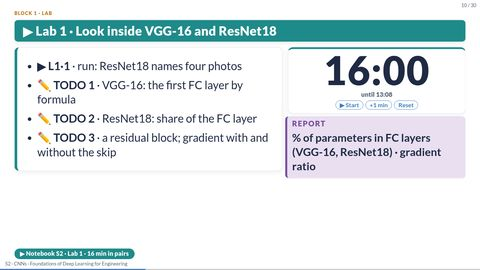

<sub>Slide 10 · Lab 1</sub>

16 minutes, in pairs. Two famous networks:

- **VGG-16** (2014): 13 convolutions, all 3 × 3, then three fully connected (FC) layers. 138 million parameters.
- **ResNet18** (2015): 17 convolutions in **residual blocks** y = x + F(x), then global average pooling and one FC layer. 11.7 million parameters.

Steps: ▶ L1·1 (run), ✏️ TODO 1, TODO 2, TODO 3, then the REPORT line.

**You report:** % of the parameters in the FC layers (VGG-16, ResNet18) and the gradient ratio skip/plain

### ▶ L1·1 · ResNet18 names four photos

ResNet18 was trained on ImageNet: 1.28 million photos of 1,000 classes. We give it our four photos (224 × 224, normalized with the ImageNet mean and standard deviation) and print its top-3 classes with their confidence. The probabilities come from a softmax applied **outside** the model.

**Look at the wrong answers.** "astronaut" and "rocket" are not among the 1,000 ImageNet classes, so the network cannot say them: it must answer with the closest class it knows ("bobsled", "drilling platform"). A classifier always gives an answer; a **low confidence** (here about 9% for the astronaut) is the warning that the answer may be meaningless.

In [ ]:
# ▶ S2·L1·1
@torch.no_grad()
def top_k(x, k=3):
    """The k most likely ImageNet classes of image x (pixels in [0, 1]) as (name, probability)."""
    resnet.eval()
    p = F.softmax(resnet(imagenet_norm(x)), dim=1)[0]          # softmax here, never inside the model
    vals, idx = p.topk(k)
    return [(categories[i], v.item()) for v, i in zip(vals, idx)]


fig, ax = plt.subplots(1, 4, figsize=(13, 3.6))
for a, (name, x) in zip(ax, PHOTOS_224.items()):
    top = top_k(x)
    REF["lab1"]["top1"][name] = top[0][0]
    print(f"{name:10s} " + " · ".join(f"{c} {100 * p:.1f}%" for c, p in top))
    a.imshow(x[0].permute(1, 2, 0).cpu()); a.axis("off")
    a.set_title(f"{top[0][0]} ({100 * top[0][1]:.0f}%)", fontsize=10)
plt.tight_layout(); plt.show()
for name, x in PHOTOS_224.items():
    c, p = top_k(x, 1)[0]
    if p < 0.5:
        print(f"warning: '{name}' -> {c} at only {100 * p:.0f}%: the network is not sure (is '{name}' one of its classes?)")
check(len(categories) == 1000, "ResNet18 chooses among 1,000 ImageNet classes", "rerun S2·0")

### ✏️ Lab 1 · TODO 1 · VGG-16: where are the 138 million parameters?

*Slide: "VGG-16" (slide 8).*

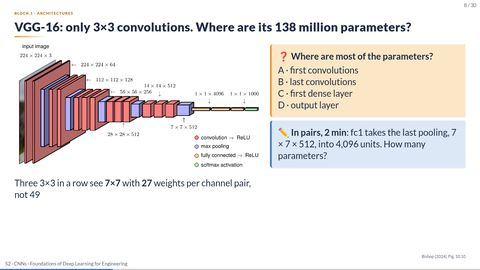

<sub>Slide 8 · VGG-16</sub>

After its last pooling, VGG-16 has 512 feature maps of 7 × 7. They are flattened and go to three FC layers:

- fc1: Linear(7 · 7 · 512 → 4,096), fc2: Linear(4,096 → 4,096), fc3: Linear(4,096 → 1,000).

A Linear layer with n_in inputs and n_out outputs has n_in · n_out weights plus n_out biases. Write fc1 by the formula, then the share of the three FC layers in the whole network. The total comes from `torchvision.models.vgg16(weights=None)`: random weights, nothing is downloaded.

In [ ]:
# ✏️ S2·L1·TODO1
fc1 = 7 * 7 * ___ * 4096 + ___            # weights + biases of Linear(7·7·512 → 4096)
fc2 = 4096 * 4096 + 4096
fc3 = 4096 * 1000 + 1000
fc_total = fc1 + fc2 + fc3

if FAST:                                        # FAST test mode: skip building the 138-million network
    vgg_total = 138_357_544
else:
    vgg = torchvision.models.vgg16(weights=None)
    vgg_total = count_params(vgg)
    print(f"PyTorch: first FC layer of VGG-16 has {count_params(vgg.classifier[0]):,} parameters")
    del vgg
fc_share = fc_total / ___
print(f"fc1 {fc1:,} · three FC layers {fc_total:,} · whole VGG-16 {vgg_total:,}")
print(f"share of the three FC layers: {100 * fc_share:.1f}%   (fc1 alone: {100 * fc1 / vgg_total:.1f}%)")

In [ ]:
# ▶ S2·L1·TODO1·check
check(fc1 == 102_764_544, "fc1 = 7·7·512·4,096 + 4,096 = 102,764,544",
      "25,088 inputs (7 · 7 · 512) times 4,096 outputs, plus 4,096 biases")
check(vgg_total == 138_357_544, "VGG-16 has 138,357,544 parameters", "count_params(vgg16(weights=None))")
check(abs(fc_share - 0.8936) < 0.001, f"the three FC layers hold {100 * fc_share:.1f}% of VGG-16",
      "fc_share = fc_total / vgg_total")
REF["lab1"].update(vgg_total=vgg_total, vgg_fc1=fc1, vgg_fc_share=round(fc_share, 4))

### ✏️ Lab 1 · TODO 2 · ResNet18: how big is its head?

The FC layer of ResNet18 is `resnet.fc`. Count its parameters with `count_params` and divide by the whole network.

In [ ]:
# ✏️ S2·L1·TODO2
print(resnet.avgpool, "->", resnet.fc)
fc_resnet = count_params(resnet.___)
resnet_total = count_params(resnet)
resnet_fc_share = fc_resnet / resnet_total
print(f"ResNet18: fc {fc_resnet:,} of {resnet_total:,} parameters = {100 * resnet_fc_share:.1f}%")

In [ ]:
# ▶ S2·L1·TODO2·check
check(fc_resnet == 513_000, "fc = Linear(512 → 1,000): 512·1,000 + 1,000 = 513,000", "count_params(resnet.fc)")
check(resnet_total == 11_689_512 and abs(resnet_fc_share - 0.0439) < 0.0005,
      f"ResNet18 has 11,689,512 parameters; its FC layer only {100 * resnet_fc_share:.1f}%",
      "resnet_fc_share = fc_resnet / resnet_total")
REF["lab1"].update(resnet_total=resnet_total, resnet_fc_share=round(resnet_fc_share, 4))

### ✏️ Lab 1 · TODO 3 · A residual block, and the gradient with and without the skip

*Slide: "ResNet" (slide 9).*

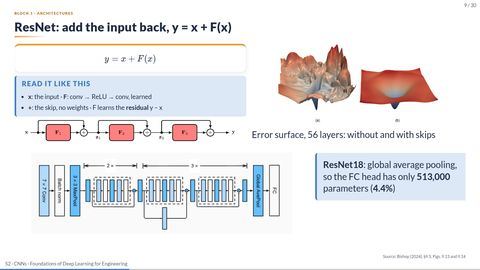

<sub>Slide 9 · ResNet</sub>

A residual block adds its input back: **y = ReLU(x + F(x))**, where F is two layers (here Linear → ReLU → Linear). A plain block computes only y = ReLU(F(x)). Complete the `return` line of the residual block.

In [ ]:
# ✏️ S2·L1·TODO3
class Block(nn.Module):
    """F(x) = Linear → ReLU → Linear. With skip: y = ReLU(x + F(x)). Without: y = ReLU(F(x))."""
    def __init__(self, width, skip=True):
        super().__init__()
        self.f = nn.Sequential(nn.Linear(width, width), nn.ReLU(), nn.Linear(width, width))
        self.skip = skip

    def forward(self, x):
        if self.skip:
            return F.relu(___ + self.f(x))       # residual block: add the input back
        return F.relu(self.f(x))                 # plain block

In [ ]:
# ▶ S2·L1·TODO3·check
blk_skip, blk_plain = Block(4, skip=True), Block(4, skip=False)
for b in (blk_skip, blk_plain):
    for p in b.parameters():
        nn.init.zeros_(p)                        # F(x) = 0: the block has learned "nothing"
x_test = torch.rand(3, 4)                        # positive inputs, as after a ReLU
check(torch.allclose(blk_skip(x_test), x_test), "with F = 0 the residual block returns its input: y = x + 0 = x",
      "return F.relu(x + self.f(x)): add the input x to F(x)")
check(torch.all(blk_plain(x_test) == 0), "with F = 0 the plain block returns 0: the signal is lost",
      "do not change the plain branch")

### ▶ L1·3 · The gradient at the first layer, with and without skips

We stack **5 blocks** (10 Linear layers of width 128) plus a Linear(128, 10) output, once with plain blocks and once with residual blocks. Same initialization (PyTorch default), same random batch, at the start of training. We measure the mean size of the gradient that reaches the weights of the **first** layer.

This runs on the CPU with a fixed seed, so every pair gets exactly the same numbers.

In [ ]:
# ▶ S2·L1·3
WIDTH, DEPTH = 128, 5                 # 5 blocks = 10 Linear layers


def first_layer_grad(depth, skip, seed=0, width=WIDTH):
    """Mean |gradient| of the weights of the FIRST Linear layer, at initialization, on one random batch (CPU)."""
    torch.manual_seed(seed)
    net = nn.Sequential(*[Block(width, skip) for _ in range(depth)], nn.Linear(width, 10))
    g = torch.Generator().manual_seed(1000 + seed)
    x = torch.randn(64, width, generator=g)             # a random batch of 64 inputs
    y = torch.randint(0, 10, (64,), generator=g)        # random labels
    F.cross_entropy(net(x), y).backward()
    return net[0].f[0].weight.grad.abs().mean().item()


grad_plain = first_layer_grad(DEPTH, skip=False)
grad_skip = first_layer_grad(DEPTH, skip=True)
grad_ratio = grad_skip / grad_plain
print(f"{DEPTH} blocks · gradient at the first layer: plain {grad_plain:.2e} · with skips {grad_skip:.2e}")
print(f"ratio skip / plain: {grad_ratio:,.0f}")
print(f"Meaning: without skips the first layer gets about {grad_ratio:,.0f} times less gradient, so it learns about "
      f"{grad_ratio:,.0f} times more slowly than with skips.\nWith y = x + F(x) the gradient has a direct path "
      "back through every '+ x', so even the first layer gets a useful signal.")

depths = list(range(1, 31))
g_plain = [first_layer_grad(d, skip=False) for d in depths]
g_skip = [first_layer_grad(d, skip=True) for d in depths]
plt.figure(figsize=(7, 3.4))
plt.semilogy(depths, g_plain, "o-", color=MLP_COLOR, ms=3, label="plain blocks")
plt.semilogy(depths, g_skip, "o-", color=CNN_COLOR, ms=3, label="residual blocks (skip)")
plt.axvline(DEPTH, color="grey", ls=":", lw=1)
plt.xlabel("number of blocks (2 Linear layers each)"); plt.ylabel("mean |gradient| at layer 1 (log scale)")
plt.title("The gradient vanishes without skips"); plt.legend(); plt.tight_layout(); plt.show()
print(f"at 30 blocks the ratio is about 10^{np.log10(g_skip[-1] / g_plain[-1]):.0f}")

check(grad_skip > 10 * grad_plain, f"the skips keep the gradient {grad_ratio:,.0f} times larger at the first layer",
      "TODO 3: the residual block must return F.relu(x + self.f(x))")
REF["lab1"].update(grad_plain=float(f"{grad_plain:.4g}"), grad_skip=float(f"{grad_skip:.4g}"),
                   grad_ratio=round(grad_ratio, 1))
save_reference(quiet=True)
fc_v = 100 * REF["lab1"]["vgg_fc_share"] if REF["lab1"]["vgg_fc_share"] else float("nan")
fc_r = 100 * REF["lab1"]["resnet_fc_share"] if REF["lab1"]["resnet_fc_share"] else float("nan")
report_line("Lab 1", f"% of parameters in FC layers · VGG-16 {fc_v:.1f} · ResNet18 {fc_r:.1f} · "
                     f"gradient ratio skip/plain {grad_ratio:,.0f}")

💬 **Lab 1 · Q1.** VGG-16 keeps 89% of its parameters in its three FC layers; ResNet18 only 4.4% in its one FC layer. What does ResNet18 do just before `fc` that makes its head so small? (Look at the line `AdaptiveAvgPool2d` printed in TODO 2.)

✍️ **Your answer:** *(double-click here and write)*

&nbsp;

❓ **Lab 1 · Q2.** In a residual block y = x + F(x), suppose F learns to output 0. What does the block compute?
(a) zero  (b) the identity, y = x  (c) 2x  (d) random noise

✍️ **Your answer:** *(double-click here and write)*

&nbsp;

### ★ Optional · Deeper stacks

For fast pairs. How does the ratio grow with the number of blocks? Each plain block shrinks the gradient by about the same factor, so the ratio grows exponentially (a straight line on the log plot above).

In [ ]:
# ▶ S2·L1·STAR
for d in (2, 5, 10, 20, 30):
    print(f"{d:2d} blocks: ratio skip / plain = {first_layer_grad(d, True) / first_layer_grad(d, False):.3g}")

## Lab 2 · Grad-CAM, then fool the network

*Slide: "Lab 2" (slide 15).*

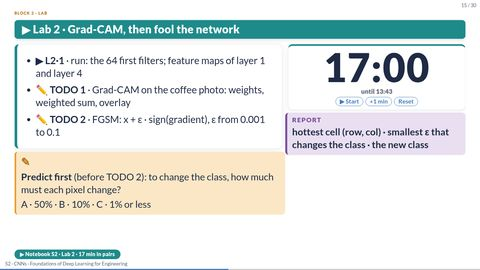

<sub>Slide 15 · Lab 2</sub>

17 minutes, in pairs. Steps: ▶ L2·1 (run), ✏️ TODO 1 Grad-CAM, ✏️ TODO 2 an adversarial image, then the REPORT line. L2·1 looks at the cat; TODO 1 and TODO 2 use the **coffee** photo (ResNet18 says "espresso" with 93%).

**You report:** the hottest Grad-CAM cell (row, col), the smallest ε that changes the class, and the new class

### ▶ L2·1 · What the first and the last layers see

- The **64 filters of the first layer** of ResNet18 (`conv1`, each 3 × 7 × 7), shown as small colour images. Look for edges at several angles and colour blobs.
- **Feature maps** of the cat: 8 of the 64 maps after `layer1` (56 × 56, still the shape of the cat) and 8 of the 512 maps after `layer4` (7 × 7, only "where" something important is).

In [ ]:
# ▶ S2·L2·1
w1 = resnet.conv1.weight.detach().cpu()                     # (64, 3, 7, 7)
print("conv1 weights:", tuple(w1.shape))
show_grid(w1, ncols=16, size=0.75)                          # each filter scaled to [0, 1] as an RGB tile

maps = {}


def save_output(name):
    """A forward hook: keeps the output of a layer in maps[name]."""
    def hook(module, inp, out):
        maps[name] = out.detach()
    return hook


hooks = [resnet.layer1.register_forward_hook(save_output("layer1")),
         resnet.layer4.register_forward_hook(save_output("layer4"))]
with torch.no_grad():
    resnet(imagenet_norm(PHOTOS_224["cat"]))
for h in hooks:
    h.remove()                                              # always remove hooks you do not need any more
print("layer1 output:", tuple(maps["layer1"].shape), "· layer4 output:", tuple(maps["layer4"].shape))
show_grid(maps["layer1"][0, :8], [f"layer1 · map {c}" for c in range(8)], cmap="viridis", size=1.6)
show_grid(maps["layer4"][0, :8], [f"layer4 · map {c}" for c in range(8)], cmap="viridis", size=1.6)
check(tuple(maps["layer4"].shape) == (1, 512, 7, 7), "layer4 gives 512 maps of 7 × 7 for a 224 × 224 photo",
      "rerun S2·0 and this cell")

### ✏️ Lab 2 · TODO 1 · Grad-CAM: which region pushed the score of this class?

*Slide: "Grad-CAM" (slide 14).*

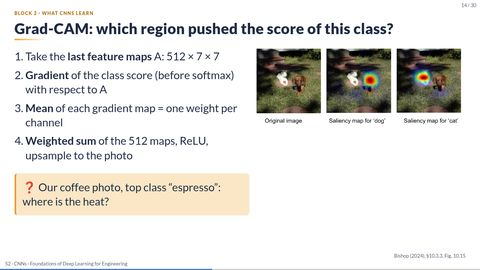

<sub>Slide 14 · Grad-CAM</sub>

Grad-CAM in three steps, on the output of `layer4` (512 maps of 7 × 7):

1. a **forward hook** keeps the maps `acts` (1, 512, 7, 7); a **gradient hook** keeps `grads`, the gradient of the class score with respect to these maps (same shape),
2. the **weight** of each map is the mean of its gradient over the 7 × 7 positions (dimensions 2 and 3),
3. the heat map is the weighted **sum over the 512 maps** (dimension 1), then a ReLU (keep only what pushes the score up).

We use the coffee photo: which part of it makes ResNet18 say "espresso"?

The hooks are written for you. Fill in the two dimensions of the mean and the dimension of the sum.

In [ ]:
# ✏️ S2·L2·TODO1
def grad_cam(x, class_idx=None):
    """Grad-CAM map (1, 7, 7) of image x (pixels in [0, 1]) for one class (None = the top-1 class)."""
    store = {}

    def save_grad(g):                            # gradient hook: d(score) / d(acts)
        store["grads"] = g

    def save_acts(module, inp, out):             # forward hook on layer4
        store["acts"] = out
        out.register_hook(save_grad)

    handle = resnet.layer4.register_forward_hook(save_acts)
    try:
        logits = resnet(imagenet_norm(x))
        if class_idx is None:
            class_idx = logits.argmax(dim=1).item()
        logits[0, class_idx].backward()          # gradient of ONE class score
    finally:
        handle.remove()
        resnet.zero_grad(set_to_none=True)
    acts, grads = store["acts"].detach(), store["grads"]      # both (1, 512, 7, 7)
    w = grads.mean(dim=(___, ___), keepdim=True)               # (1, 512, 1, 1): one weight per map
    cam = F.relu((w * acts).sum(dim=___))                      # (1, 7, 7): weighted sum of the 512 maps
    return cam, class_idx


CLASS = None            # None = the top-1 class (espresso). Try another one, e.g. CLASS = categories.index("cup")
cam, cam_cls = grad_cam(PHOTOS_224["coffee"], CLASS)
print("class:", categories[cam_cls], "· map", tuple(cam.shape))
print((cam[0] / cam.max()).cpu().numpy().round(2))

In [ ]:
# ▶ S2·L2·TODO1·check
check(tuple(cam.shape) == (1, 7, 7), "Grad-CAM map (1, 7, 7): one value per position of layer4",
      "mean over the positions (dims 2 and 3), sum over the 512 maps (dim 1)")
check(cam.max().item() > 0, "the map has positive values (the ReLU keeps what pushes the score up)",
      "F.relu((w * acts).sum(dim=1))")
hot_cell = divmod(cam[0].argmax().item(), 7)               # (row, col) of the largest value
print(f"hottest cell (row, col) = {hot_cell} for class '{categories[cam_cls]}'")

heat = F.interpolate(cam[None], size=224, mode="bilinear", align_corners=False)[0, 0].cpu()
fig, ax = plt.subplots(1, 3, figsize=(11, 3.8))
ax[0].imshow(PHOTOS_224["coffee"][0].permute(1, 2, 0).cpu()); ax[0].set_title("photo")
ax[1].imshow(cam[0].cpu(), cmap="jet"); ax[1].set_title("Grad-CAM 7 × 7")
ax[1].set_xticks(range(7)); ax[1].set_yticks(range(7))
ax[2].imshow(PHOTOS_224["coffee"][0].permute(1, 2, 0).cpu()); ax[2].imshow(heat, cmap="jet", alpha=0.45)
ax[2].set_title(f"overlay · {categories[cam_cls]}")
ax[0].axis("off"); ax[2].axis("off"); plt.tight_layout(); plt.show()
if CLASS is None:
    REF["lab2"].update(cam_class=categories[cam_cls], cam_cell=list(hot_cell))

### ✏️ Lab 2 · TODO 2 · Fool the network (FGSM)

*Slide: "fooled" (slide 16).*

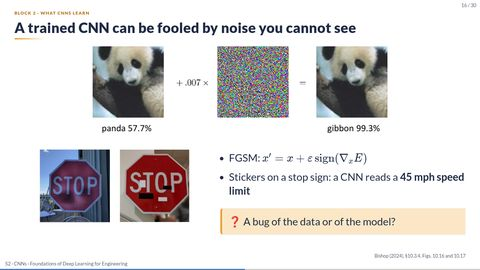

<sub>Slide 16 · fooled</sub>

The **fast gradient sign method** moves every pixel by a tiny amount ε in the direction that increases the loss:

$$x_{adv} = \text{clip}\big(x + \varepsilon \cdot \text{sign}(\nabla_x \text{loss}),\ 0,\ 1\big)$$

Pixels are in [0, 1], so ε = 0.01 means 1% of the full range per pixel. The normalization is inside the wrapper `Normalized`, so we change real pixels. We attack the coffee photo ("espresso"). Fill in the step: ε times the **sign** of the gradient.

**Predict first** (slide 15): how much must each pixel change to change the class? A 50%, B 10%, C 1% or less.

In [ ]:
# ✏️ S2·L2·TODO2
class Normalized(nn.Module):
    """Pixels in [0, 1] in, logits out: the ImageNet normalization is inside the model."""
    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, x):
        return self.model(imagenet_norm(x))


net = Normalized(resnet).eval()
EPS = [0.001, 0.002, 0.005, 0.01, 0.02, 0.05, 0.1]
x = PHOTOS_224["coffee"].clone().requires_grad_(True)
logits = net(x)
y_clean = logits.argmax(dim=1)                       # the class the network sees now
F.cross_entropy(logits, y_clean).backward()          # x.grad: how the loss changes with each pixel
resnet.zero_grad(set_to_none=True)
p_clean = F.softmax(logits.detach(), dim=1)[0, y_clean].item()
print(f"clean photo: {categories[y_clean.item()]} ({100 * p_clean:.1f}%)")

fgsm = []
with torch.no_grad():
    for eps in EPS:
        x_adv = (x + ___ * x.grad.___()).clamp(0, 1)    # every pixel moves by +eps or -eps
        p = F.softmax(net(x_adv), dim=1)[0]
        fgsm.append((eps, p.argmax().item(), p.max().item(), x_adv))
        print(f"ε = {eps:<6} top-1: {categories[fgsm[-1][1]]:22s} {100 * fgsm[-1][2]:5.1f}%")

In [ ]:
# ▶ S2·L2·TODO2·check
changed = [r for r in fgsm if r[1] != y_clean.item()]
check(abs((fgsm[0][3] - x).abs().max().item() - EPS[0]) < 1e-4 or EPS[0] == 0,
      "each pixel moved by at most ε", "x_adv = x + eps * x.grad.sign(), then clamp to [0, 1]")
check(len(changed) > 0, "a change you cannot see changes the class", "use the sign of x.grad, times eps")
if changed:
    eps_found, cls_found, conf_found, x_found = changed[0]
    delta = (x_found - x.detach())[0]
    fig, ax = plt.subplots(1, 3, figsize=(11, 3.8))
    ax[0].imshow(x.detach()[0].permute(1, 2, 0).cpu())
    ax[0].set_title(f"clean: {categories[y_clean.item()]} ({100 * p_clean:.0f}%)")
    ax[1].imshow((0.5 + 0.5 * delta / eps_found).permute(1, 2, 0).cpu().clamp(0, 1))
    ax[1].set_title(f"noise ±{eps_found} (scaled to be visible)")
    ax[2].imshow(x_found[0].permute(1, 2, 0).cpu())
    ax[2].set_title(f"ε = {eps_found}: {categories[cls_found]} ({100 * conf_found:.0f}%)")
    for a in ax:
        a.axis("off")
    plt.tight_layout(); plt.show()
    REF["lab2"].update(fgsm_eps=eps_found, fgsm_class=categories[cls_found])
save_reference(quiet=True)
cell_txt = str(tuple(REF["lab2"]["cam_cell"])) if REF["lab2"]["cam_cell"] else "(do TODO 1)"
eps_txt = f"{eps_found} · new class {categories[cls_found]}" if changed else "none"
report_line("Lab 2", f"Grad-CAM hottest cell {cell_txt} · smallest ε {eps_txt}")

💬 **Lab 2 · Q1.** Where is the heat for "espresso": on the cup, the coffee and its crema, the saucer, the table? Is it where you expected? Set `CLASS = categories.index("cup")` or a class that is not in the photo (for example `"tiger cat"`) in TODO 1, rerun it and its ✅ cell, and compare.

✍️ **Your answer:** *(double-click here and write)*

&nbsp;

❓ **Lab 2 · Q2.** The adversarial photo looks exactly like the clean one to you, yet the network changes its answer. Is this a weakness (a) of the photo, or (b) of the model?

✍️ **Your answer:** *(double-click here and write)*

&nbsp;

### ★ Optional · Grad-CAM on the cat and the astronaut

For fast pairs. On the cat, the face fills the photo, so the map is spread almost everywhere (compare with the coffee cup). The astronaut photo has several objects and no ImageNet class "astronaut": which class does ResNet18 choose, and where does it look?

In [ ]:
# ▶ S2·L2·STAR
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
for a, name in zip(ax, ("cat", "astronaut")):
    cam_o, cls_o = grad_cam(PHOTOS_224[name])
    heat_o = F.interpolate(cam_o[None], size=224, mode="bilinear", align_corners=False)[0, 0].cpu()
    share = (cam_o > 0.5 * cam_o.max()).float().mean().item()
    print(f"{name}: {categories[cls_o]} · {100 * share:.0f}% of the 49 cells are above half the maximum")
    a.imshow(PHOTOS_224[name][0].permute(1, 2, 0).cpu()); a.imshow(heat_o, cmap="jet", alpha=0.45)
    a.set_title(f"{name} · {categories[cls_o]}"); a.axis("off")
plt.tight_layout(); plt.show()

## Lab 3 · Transfer learning: reuse 11 million weights

Every pair does this lab: 3a until 14:46, 3b until 15:03.

ResNet18 already knows edges, textures and object parts from 1.28 million ImageNet photos. We keep this **backbone** and give it a new **head** for the 10 classes of CIFAR-10. Two recipes:

- **Recipe 1 · feature extraction** (Lab 3a): freeze the backbone, train only the new head (5,130 parameters).
- **Recipe 2 · fine-tuning** (Lab 3b): then unfreeze everything and train all 11 million weights with a learning rate 10 times smaller.

**You report:** accuracy (%) after feature extraction (3a); after fine-tuning (3b); with a learning rate 100 times too large (🔬)

### ▶ L3·1 · 5,000 CIFAR-10 photos, and a CNN from scratch to beat

*Slide: "Keep the backbone" (slide 20).*

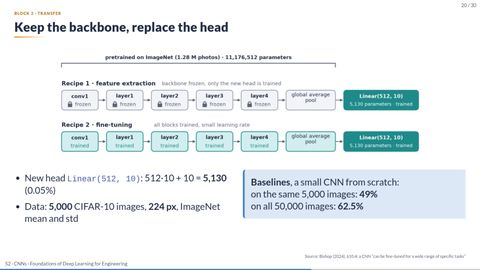

<sub>Slide 20 · Keep the backbone</sub>

- We take only **5,000 training photos** (500 per class) and 2,000 validation photos (200 per class, from the test set). They stay 32 × 32 on the GPU.
- ResNet18 expects 224 × 224 photos normalized like ImageNet: `prep(x)` resizes each batch to 224 and normalizes it, on the fly.
- A baseline: the small ConvNet of the warm-up (67,642 parameters), trained from scratch on the same 5,000 photos for 10 epochs. This is the number to beat.

In [ ]:
# ▶ S2·L3·1
N3_TRAIN, N3_VAL, IMG = (400, 200, 96) if FAST else (5_000, 2_000, 224)


def stratified(y, n, seed=0):
    """Indices of n examples, n/10 of each class, in random order."""
    g = torch.Generator().manual_seed(seed)
    idx = [(y == c).nonzero()[:, 0] for c in range(10)]
    idx = torch.cat([i[torch.randperm(len(i), generator=g)[:n // 10]] for i in idx])
    return idx[torch.randperm(len(idx), generator=g)]


tr3, va3 = stratified(CIFAR_Y_TRAIN, N3_TRAIN, seed=0), stratified(CIFAR_Y_TEST, N3_VAL, seed=1)
X3_train = (CIFAR_X_TRAIN[tr3].float() / 255).to(device)      # (5000, 3, 32, 32), pixels in [0, 1]
X3_val = (CIFAR_X_TEST[va3].float() / 255).to(device)          # (2000, 3, 32, 32)
y3_train, y3_val = CIFAR_Y_TRAIN[tr3].to(device), CIFAR_Y_TEST[va3].to(device)
print(f"train {tuple(X3_train.shape)} · val {tuple(X3_val.shape)} · per class {torch.bincount(y3_train).tolist()}")


def prep(x):
    """A batch of 32 × 32 photos in [0, 1] -> IMG × IMG (224), normalized like ImageNet."""
    x = F.interpolate(x, size=(IMG, IMG), mode="bilinear", align_corners=False)
    return imagenet_norm(x)


print("prep:", tuple(X3_train[:2].shape), "->", tuple(prep(X3_train[:2]).shape))


class SmallConvNet(nn.Module):
    """The warm-up ConvNet (67,642 parameters), written again so that this lab does not need the warm-up."""
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 8, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(8, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2))
        self.head = nn.Sequential(nn.Flatten(), nn.Linear(16 * 8 * 8, 64), nn.ReLU(), nn.Linear(64, 10))

    def forward(self, x):
        return self.head(self.features(x))               # logits, no softmax


m3, s3 = X3_train.mean(dim=(0, 2, 3), keepdim=True), X3_train.std(dim=(0, 2, 3), keepdim=True)
set_seed(0)
scratch = SmallConvNet()
fit(scratch, (X3_train - m3) / s3, y3_train, (X3_val - m3) / s3, y3_val, epochs=10, name="from scratch · 5,000 photos")
r_s = result("from scratch · 5,000 photos")
REF["lab3"].update(n_train=N3_TRAIN, n_val=N3_VAL, img_size=IMG,
                   scratch5k={"val_acc": round(r_s["val_acc"], 4), "time_s": r_s["time_s"]})
thr = 0.20 if FAST else 0.44                     # reference run (Colab T4): 49.3% (FAST: 30 to 34%)
check(r_s["val_acc"] > thr, f"from scratch on 5,000 photos: {100 * r_s['val_acc']:.1f}% (the number to beat)",
      "rerun this cell")

### ▶ L3·2 · The training loop for transfer learning (read it, then run it)

The same four steps as always (forward, loss, backward, update), with two additions for speed:

- `prep` makes each batch 224 × 224 on the fly (the GPU keeps only the small 32 × 32 photos),
- **mixed precision** on the GPU (`torch.autocast`, float16): about 2 times faster on a T4. It does nothing on a CPU.

`freeze_bn=True` keeps the whole model in eval mode while training (used in Lab 3a).

In [ ]:
# ▶ S2·L3·2
BATCH3 = 64


def amp():
    """Mixed precision (float16) on the GPU; nothing on a CPU."""
    return torch.autocast(device_type="cuda", dtype=torch.float16) if device == "cuda" else contextlib.nullcontext()


@torch.no_grad()
def evaluate_tl(model, batch_size=250):
    """Validation accuracy (0 to 1) on X3_val, in batches."""
    model.eval()
    correct = 0
    for i in range(0, len(X3_val), batch_size):
        with amp():
            out = model(prep(X3_val[i:i + batch_size]))
        correct += (out.argmax(dim=1) == y3_val[i:i + batch_size]).sum().item()
    return correct / len(X3_val)


def train_tl(model, optimizer, epochs, name, freeze_bn=False):
    """Train on X3_train (resized by prep), one line per epoch. Returns dict(val_acc, time_s)."""
    scaler = torch.amp.GradScaler("cuda") if device == "cuda" else None    # float16 needs a loss scaler
    loss_fn = nn.CrossEntropyLoss()
    n, t0 = len(X3_train), time.time()
    for epoch in range(epochs):
        # BatchNorm: train mode updates its running statistics, eval mode keeps the ImageNet ones
        model.eval() if freeze_bn else model.train()
        perm = torch.randperm(n, device=device)
        total = torch.zeros((), device=device)
        for i in range(0, n, BATCH3):
            idx = perm[i:i + BATCH3]
            with amp():
                loss = loss_fn(model(prep(X3_train[idx])), y3_train[idx])     # 1. forward, 2. loss
            optimizer.zero_grad(set_to_none=True)
            if scaler is not None:
                scaler.scale(loss).backward()                                  # 3. backward
                scaler.step(optimizer)                                         # 4. update
                scaler.update()
            else:
                loss.backward()
                optimizer.step()
            total += loss.detach().float() * len(idx)
        acc = evaluate_tl(model)
        print(f"{name} · epoch {epoch + 1}/{epochs} · train loss {total.item() / n:.3f} · "
              f"val acc {100 * acc:.1f}% · {time.time() - t0:.0f} s")
    t = round(time.time() - t0, 1)
    RESULTS.append(dict(name=name, params=count_params(model), val_acc=acc, errors=int(round((1 - acc) * len(y3_val))),
                        n_val=len(y3_val), epochs=epochs, time_s=t))
    return dict(val_acc=acc, time_s=t)


EPOCHS3 = 1 if FAST else 2
print(f"ready: {len(X3_train):,} training photos, batches of {BATCH3}, images {IMG} × {IMG}, "
      f"mixed precision {'on' if device == 'cuda' else 'off'}")

### ✏️ Lab 3a · TODO 1 · Recipe 1: freeze the backbone, train a new head

*Slide: "Recipe 1" (slide 21).*

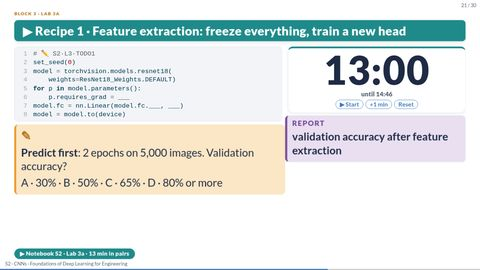

<sub>Slide 21 · Recipe 1</sub>

1. Load ResNet18 with its ImageNet weights (already downloaded in `S2·0`).
2. **Freeze** every parameter: `requires_grad = False` means no gradient and no update.
3. Replace the head: `model.fc` becomes a new `nn.Linear` from the 512 features (`model.fc.in_features`) to our 10 classes. A new layer is trainable by default.

Only the head learns: 512 · 10 + 10 = 5,130 parameters, 0.05% of the network. Training 2 epochs takes about 6 s on a T4.

**Predict first** (slide 21): validation accuracy after 2 epochs? A 30%, B 50%, C 65%, D 80% or more.

In [ ]:
# ✏️ S2·L3·TODO1
set_seed(0)
model = torchvision.models.resnet18(weights=ResNet18_Weights.DEFAULT)   # pretrained on ImageNet
for p in model.parameters():
    p.requires_grad = ___                                         # freeze: no gradient, no update
model.fc = nn.Linear(model.fc.___, ___)                    # new head: 512 → 10 classes
model = model.to(device)
print(f"trainable parameters: {count_params(model):,} of {sum(p.numel() for p in model.parameters()):,}")

In [ ]:
# ▶ S2·L3·TODO1·check
check(count_params(model) == 5130, "only the new head is trainable: 512·10 + 10 = 5,130 parameters",
      "requires_grad = False for every old parameter; the new Linear(512, 10) is created after the loop")
check(model.fc.out_features == 10, "the head has 10 outputs, one per CIFAR-10 class", "nn.Linear(512, 10)")

In [ ]:
# ▶ S2·L3·TODO1·train
set_seed(0)
optimizer = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=1e-3)
# freeze_bn=True: the frozen backbone keeps its ImageNet BatchNorm statistics, so the features the head learns from do not move
fe = train_tl(model, optimizer, EPOCHS3, "feature extraction (head only)", freeze_bn=True)
fe_state = {k: v.detach().clone() for k, v in model.state_dict().items()}   # saved for TODO 3
REF["lab3"]["fe"] = {"val_acc": round(fe["val_acc"], 4), "time_s": fe["time_s"], "trainable": count_params(model)}
save_reference(quiet=True)
thr = 0.18 if FAST else 0.80                     # reference run (Colab T4): 83.5% (FAST: 28 to 31%)
check(fe["val_acc"] > thr, f"feature extraction: {100 * fe['val_acc']:.1f}% after training only 5,130 parameters",
      "TODO 1 first (trainable must be 5,130), then rerun this cell")
s5k = REF["lab3"]["scratch5k"]["val_acc"]
report_line("Lab 3a", f"feature extraction accuracy in % · {100 * fe['val_acc']:.1f}"
            + (f" (from scratch: {100 * s5k:.1f})" if s5k else ""))

❓ **Lab 3a · Q1.** Your prediction (A 30%, B 50%, C 65%, D 80% or more) and your result. Only 5,130 parameters learned, from 5,000 photos. Why is this so much better than the CNN trained from scratch on the same photos?

✍️ **Your answer:** *(double-click here and write)*

&nbsp;

### ✏️ Lab 3b · TODO 2 · Recipe 2: unfreeze everything, learning rate 10 times smaller

*Slide: "Recipe 2" (slide 22).*

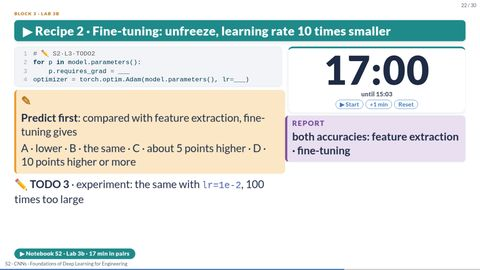

<sub>Slide 22 · Recipe 2</sub>

We continue from the model of Lab 3a (its head is already trained). Now **every** parameter learns, with Adam and a learning rate of 1e-4, 10 times smaller than for the head: the pretrained weights are already good, so we only want to adjust them a little. Training 2 epochs takes about 16 s on a T4.

**Predict first** (slide 22): compared with feature extraction, the accuracy will be A lower, B the same, C about 5 points higher, D 10 points higher or more.

In [ ]:
# ✏️ S2·L3·TODO2
for p in model.parameters():
    p.requires_grad = ___                                       # unfreeze every layer
optimizer = torch.optim.Adam(model.parameters(), lr=___)        # 10 times smaller than for the head
print(f"trainable parameters: {count_params(model):,}")

In [ ]:
# ▶ S2·L3·TODO2·check
check(count_params(model) == 11_181_642, "all 11,181,642 parameters are trainable (11,176,512 backbone + 5,130 head)",
      "requires_grad = True for every parameter; run TODO 1 and its training cell first")
check(abs(optimizer.param_groups[0]["lr"] - 1e-4) < 1e-12, "learning rate 1e-4, 10 times smaller than 1e-3",
      "lr=1e-4")

In [ ]:
# ▶ S2·L3·TODO2·train
set_seed(0)
ft = train_tl(model, optimizer, EPOCHS3, "fine-tuning (all layers, lr 1e-4)")
REF["lab3"]["ft"] = {"val_acc": round(ft["val_acc"], 4), "time_s": ft["time_s"], "trainable": count_params(model)}
save_reference(quiet=True)
thr = 0.30 if FAST else 0.86                     # reference run (Colab T4): 90.1% (FAST: 45 to 46%)
check(ft["val_acc"] > thr, f"fine-tuning: {100 * ft['val_acc']:.1f}%", "TODO 2: lr=1e-4 and every layer trainable")
fe_acc = REF["lab3"]["fe"]["val_acc"]
report_line("Lab 3b", f"accuracy in % · feature extraction {100 * fe_acc:.1f} · fine-tuning {100 * ft['val_acc']:.1f}"
            if fe_acc else f"fine-tuning accuracy in % · {100 * ft['val_acc']:.1f}")

### 🔬 Lab 3b · TODO 3 · A learning rate 100 times too large

We restart from the end of Lab 3a (`fe_state`: pretrained backbone + trained head), unfreeze everything, and fine-tune for 1 epoch with lr = 1e-2, 100 times larger than in TODO 2. Watch the accuracy.

In [ ]:
# ✏️ S2·L3·TODO3
model_bad = torchvision.models.resnet18()                 # same architecture; the weights come from fe_state
model_bad.fc = nn.Linear(512, 10)
model_bad.load_state_dict(fe_state)                       # restart from the end of Lab 3a
model_bad = model_bad.to(device)                          # every parameter is trainable
optimizer_bad = torch.optim.Adam(model_bad.parameters(), lr=___)    # 100 times larger than in TODO 2
set_seed(0)
bad = train_tl(model_bad, optimizer_bad, 1, "fine-tuning, lr 1e-2 (too large)")

In [ ]:
# ▶ S2·L3·TODO3·check
REF["lab3"]["bad_lr"] = {"val_acc": round(bad["val_acc"], 4), "time_s": bad["time_s"]}
save_reference(quiet=True)
fe_acc = REF["lab3"]["fe"]["val_acc"] or 1.0
check(abs(optimizer_bad.param_groups[0]["lr"] - 1e-2) < 1e-12, "learning rate 1e-2", "lr=1e-2")
if FAST:
    print("(FAST mode: collapse not checked)")
else:
    check(bad["val_acc"] < fe_acc - 0.15,
          f"with lr 1e-2 the accuracy falls to {100 * bad['val_acc']:.1f}%, below feature extraction "
          f"({100 * fe_acc:.1f}%)", "lr=1e-2, and restart from fe_state")
report_line("Lab 3b 🔬", f"fine-tuning with lr 1e-2, accuracy in % · {100 * bad['val_acc']:.1f}")

❓ **Lab 3b · Q2.** Why does fine-tuning with lr = 1e-2 end far below feature extraction, although it starts from the same weights?

✍️ **Your answer:** *(double-click here and write)*

&nbsp;

💬 **Lab 3b · Q3.** Two engineering projects: (1) 300 chest X-rays labelled by a doctor; (2) 50,000 photos of products in a factory. Which recipe would you use for each, and why?

✍️ **Your answer:** *(double-click here and write)*

&nbsp;

### ★ Optional · Fine-tune only the last block

For fast pairs. A middle way: from `fe_state`, unfreeze only `layer4` and `fc` (the most specific layers) and train with lr 1e-4. Compare the accuracy and the time with full fine-tuning.

In [ ]:
# ▶ S2·L3·STAR
model_l4 = torchvision.models.resnet18()
model_l4.fc = nn.Linear(512, 10)
model_l4.load_state_dict(fe_state)
model_l4 = model_l4.to(device)
for name, p in model_l4.named_parameters():
    p.requires_grad = name.startswith(("layer4", "fc"))
print(f"trainable parameters: {count_params(model_l4):,}")
set_seed(0)
opt_l4 = torch.optim.Adam([p for p in model_l4.parameters() if p.requires_grad], lr=1e-4)
l4 = train_tl(model_l4, opt_l4, EPOCHS3, "fine-tuning layer4 + fc (lr 1e-4)")
show_results()

## Lab 4 · Upsample, then segment the cat

*Slide: "Lab 4" (slide 29).*

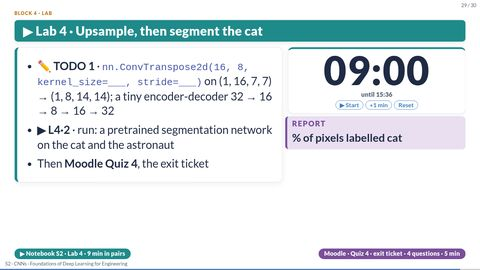

<sub>Slide 29 · Lab 4</sub>

9 minutes, in pairs. Segmentation gives a class to **every pixel**: the output is K × H × W scores (K classes). The encoder makes the maps smaller; the decoder makes them large again with **transpose convolutions**.

Steps: ✏️ TODO 1 (shapes), ▶ L4·2 (a pretrained segmentation network), then the REPORT line and Moodle Quiz 4.

**You report:** the % of the pixels of the cat photo labelled "cat"

### ✏️ Lab 4 · TODO 1 · A transpose convolution doubles the size

*Slide: "Transpose convolution" (slide 27).*

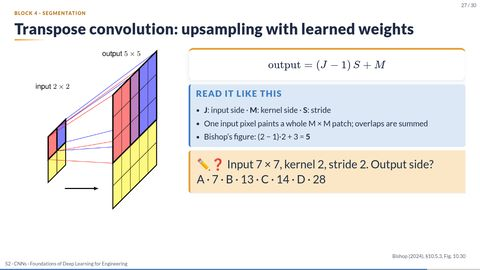

<sub>Slide 27 · Transpose convolution</sub>

Without padding, a transpose convolution gives an output of size (J − 1) · S + M. We want 7 × 7 → 14 × 14 with 16 → 8 channels. Choose the kernel size M and the stride S (hint: M = S).

In [ ]:
# ✏️ S2·L4·TODO1
up = nn.ConvTranspose2d(16, 8, kernel_size=___, stride=___)
z = torch.randn(1, 16, 7, 7)
up_out = up(z)
print(tuple(z.shape), "->", tuple(up_out.shape), "·", count_params(up), "parameters")

In [ ]:
# ▶ S2·L4·TODO1·check
check(tuple(up_out.shape) == (1, 8, 14, 14), "(7 − 1)·2 + 2 = 14: the transpose convolution doubles H and W",
      "(J − 1)·S + M = 14 with J = 7: kernel_size=2, stride=2")
check(count_params(up) == 520, "16·8·2·2 + 8 = 520 parameters", "kernel_size=2")
REF["lab4"]["up_shape"] = list(up_out.shape)

# a tiny encoder-decoder (not trained): 32 → 16 → 8 → 16 → 32, then 21 class scores per pixel
enc_dec = nn.Sequential(
    nn.Conv2d(3, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),       # encoder: 32 → 16
    nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),      #          16 → 8
    nn.ConvTranspose2d(32, 16, kernel_size=2, stride=2), nn.ReLU(),   # decoder:  8 → 16
    nn.ConvTranspose2d(16, 21, kernel_size=2, stride=2))              #          16 → 32, 21 classes
h = torch.randn(1, 3, 32, 32)
print("input", tuple(h.shape))
for layer in enc_dec:
    h = layer(h)
    if not isinstance(layer, nn.ReLU):
        print(f"{layer.__class__.__name__:16s} -> {tuple(h.shape)}")
check(tuple(h.shape) == (1, 21, 32, 32), "21 scores for each of the 32 × 32 pixels: (1, K, H, W)",
      "rerun this cell")

### ▶ L4·2 · A pretrained segmentation network on the cat and the astronaut

`lraspp_mobilenet_v3_large` is a small segmentation network (3.2 million parameters) trained on 21 classes (background, person, cat, dog, car, ...). It downloads 13 MB the first time. For each pixel we take the class with the largest score (argmax) and colour it.

In [ ]:
# ▶ S2·L4·2
SEG_OK = False
try:
    from torchvision.models.segmentation import lraspp_mobilenet_v3_large, LRASPP_MobileNet_V3_Large_Weights
    seg_weights = LRASPP_MobileNet_V3_Large_Weights.DEFAULT
    seg_model = lraspp_mobilenet_v3_large(weights=seg_weights).eval().to(device)
    VOC = seg_weights.meta["categories"]                  # 21 classes, VOC[0] = background
    SEG_OK = True
except Exception as e:
    print("Could not load the segmentation network (no internet?):", repr(e)[:120])
    print("Skip this cell: look at slide 29 instead.")

if SEG_OK:
    masks = {}
    with torch.no_grad():
        for name in ("cat", "astronaut"):
            out = seg_model(imagenet_norm(PHOTOS_FULL[name]))["out"]      # (1, 21, H, W) scores
            masks[name] = out.argmax(dim=1)[0].cpu()                     # (H, W) class of each pixel
            print(f"{name:10s} scores {tuple(out.shape)} -> mask {tuple(masks[name].shape)}")
    cmap = plt.get_cmap("tab20", 21)
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.6))
    for a, (name, m) in zip(ax, masks.items()):
        a.imshow(PHOTOS_FULL[name][0].permute(1, 2, 0).cpu())
        a.imshow(np.ma.masked_where(m.numpy() == 0, m.numpy()), cmap=cmap, vmin=0, vmax=20, alpha=0.55)
        present = [c for c in m.unique().tolist() if c != 0]
        a.set_title(name + ": " + ", ".join(f"{VOC[c]} {100 * (m == c).float().mean():.0f}%" for c in present),
                    fontsize=9)
        a.axis("off")
    plt.tight_layout(); plt.show()
    cat_pct = 100 * (masks["cat"] == VOC.index("cat")).float().mean().item()
    REF["lab4"]["cat_pct"] = round(cat_pct, 1)
    check(cat_pct > 73, f"{cat_pct:.1f}% of the pixels of the cat photo are labelled 'cat'", "rerun this cell")
    report_line("Lab 4", f"pixels labelled cat in % · {cat_pct:.1f}")
save_reference(quiet=True)

❓ **Lab 4 · Q1.** A segmentation network for 21 classes gets one photo of 224 × 224. What is the shape of its output scores?
(a) (1, 21)  (b) (1, 21, 224, 224)  (c) (1, 3, 224, 224)  (d) (1, 224, 224)

✍️ **Your answer:** *(double-click here and write)*

&nbsp;

### ★ Optional · Photos without a known object

For fast pairs. The coffee cup and the rocket are not among the 21 classes. What does the network do with them?

In [ ]:
# ▶ S2·L4·STAR
if SEG_OK:
    with torch.no_grad():
        for name in ("coffee", "rocket"):
            m = seg_model(imagenet_norm(PHOTOS_FULL[name]))["out"].argmax(dim=1)[0].cpu()
            print(name, "·", ", ".join(f"{VOC[c]} {100 * (m == c).float().mean():.1f}%" for c in m.unique().tolist()))

## Summary

| Lab | Idea | PyTorch line |
|:-|:-|:-|
| Warm-up | a CNN beats an MLP with a third of the parameters | `nn.Conv2d(3, 8, 3, padding=1)` |
| 1 · Architectures | VGG-16 keeps 89% of its weights in FC layers; ResNet adds the input back and its head is tiny | `F.relu(x + self.f(x))` |
| 2 · What CNNs learn | first layers see edges and colours; Grad-CAM shows where the class score comes from; tiny noise can fool a CNN | `grads.mean(dim=(2, 3))`, `x + eps * x.grad.sign()` |
| 3 · Transfer | freeze the backbone and train a new head, then unfreeze with a 10 times smaller learning rate | `p.requires_grad = False`, `model.fc = nn.Linear(512, 10)` |
| 4 · Segmentation | a class for every pixel; transpose convolutions upsample | `nn.ConvTranspose2d(16, 8, 2, stride=2)` |

The last cell prints all your REPORT lines and your results table.

In [ ]:
# ▶ S2·END
report()
print()
show_results()
save_reference()